In [1]:
import pandas as pd

df=pd.read_csv("Heart.csv")
print(df)

      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0      52    1   0       125   212    0        1      168      0      1.0   
1      53    1   0       140   203    1        0      155      1      3.1   
2      70    1   0       145   174    0        1      125      1      2.6   
3      61    1   0       148   203    0        1      161      0      0.0   
4      62    0   0       138   294    1        1      106      0      1.9   
...   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        0      159      0      0.0   
1024   54    1   0       120   188    0        1      113      0      1.4   

      slope  ca  thal  target  
0         2   2     3       0  
1         0

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [3]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [4]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

In [5]:
num_column = df.select_dtypes(
include=['int64', 'float64']
).columns

print(num_column)


Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')


In [6]:
cat_column = df.select_dtypes(
include=['object','str']
).columns.tolist()

print(cat_column)


[]


In [7]:
binary_cols = [col for col in df.columns if df[col].nunique() == 2]
print(binary_cols)

['sex', 'fbs', 'exang', 'target']


In [8]:
X=df.drop(columns=['target'])
y=df['target']

In [9]:
print(X.shape)
print(y.shape)

(1025, 13)
(1025,)


In [10]:
df['target'].value_counts()


target
1    526
0    499
Name: count, dtype: int64

In [11]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(820, 13)
(205, 13)
(820,)
(205,)


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.preprocessing import StandardScaler

imp=SimpleImputer(missing_values=np.nan,strategy="median")
X_train_imp = imp.fit_transform(X_train)
X_test_imp = imp.transform(X_test)

scaler=StandardScaler()
X_train_encoded=scaler.fit_transform(X_train_imp)
X_test_encoded=scaler.transform(X_test_imp)

print("X_train_encoded shape:", X_train_encoded.shape)
print("X_test_encoded shape :", X_test_encoded.shape)

X_train_encoded shape: (820, 13)
X_test_encoded shape : (205, 13)


In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

dt=DecisionTreeClassifier(random_state=42)

param_grid={
    'criterion':['gini','entropy'],
    'max_depth':[None,3,4,6,8],
    'min_samples_split':[2,4,6,7],
    'min_samples_leaf':[2,4,5,7]
}

grid=GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train_encoded,y_train)

y_pred_dt=grid.predict(X_test_encoded)

print(y_pred_dt)

    
    
    



    


[1 1 0 1 0 1 0 0 1 0 1 0 1 1 0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 0 0 1 0 1 1 1 0
 1 1 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 0 0 1 0 0 1 0 0 0 1
 1 1 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 0 1 0 1 0 1 0 1 0
 1 1 0 1 1 0 1 0 0 1 0 0 0 1 0 1 0 0 1 1 0 1 1 0 1 0 0 1 0 1 1 1 1 1 1 1 1
 0 0 0 0 1 1 0 0 0 1 0 0 1 1 0 0 1 1 0 0 1 1 0 1 1 0 1 1 1 0 0 1 1 0 1 0 1
 0 1 0 1 1 1 0 0 0 0 1 0 0 1 1 1 1 1 0 0]


In [14]:
best_model1=grid.best_estimator_
best_score=grid.best_score_
best_param=grid.best_params_

In [15]:
print(best_model1)
print(best_score)
print(best_param)

DecisionTreeClassifier(criterion='entropy', min_samples_leaf=2, random_state=42)
0.9487804878048781
{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2}


In [16]:
Acc=accuracy_score(y_test,y_pred_dt)
print(Acc)

0.9560975609756097


In [17]:
from sklearn.model_selection import KFold, cross_val_score
scores1=cross_val_score(best_model1,X_train_encoded,y_train,cv=5,scoring="accuracy")

In [18]:
print(scores1)

[0.96341463 0.92073171 0.9695122  0.9695122  0.92073171]


In [19]:
from sklearn.decomposition import PCA
pca = PCA(
n_components=2, # e.g., 0.95 or 2
random_state=42
)
X_train_pca = pca.fit_transform(X_train_encoded)
X_test_pca = pca.transform(X_test_encoded)
print(pca.explained_variance_ratio_)
print(pca.singular_values_)


[0.21121686 0.12012356]
[47.45072971 35.7843137 ]


In [20]:
dt_pca=DecisionTreeClassifier(random_state=42)
grid_search_pca = GridSearchCV(
    estimator=dt_pca,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
   
)

In [21]:
grid_search_pca.fit(X_train_pca,y_train)
y_pred_pca=grid_search_pca.predict(X_test_pca)
print(y_pred_pca)

[1 1 0 1 0 1 0 0 1 0 1 0 1 1 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 0 0 1 0 1 1 1 1
 1 1 1 0 0 1 0 0 0 0 0 0 1 1 0 0 0 1 1 0 0 1 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1
 1 1 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 0 1 0 1 0 1 0 1 1
 1 1 0 1 1 0 1 1 0 1 1 0 0 1 0 1 0 1 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1
 0 0 0 0 1 1 0 0 0 1 0 0 1 1 0 0 1 1 0 0 1 1 0 1 1 0 1 1 1 0 0 1 1 0 1 0 1
 1 1 1 1 1 1 0 0 0 0 1 0 0 1 1 1 1 1 0 0]


In [22]:
best_model2=grid_search_pca.best_estimator_
best_score=grid_search_pca.best_score_
best_param=grid_search_pca.best_params_

In [23]:
print(best_model2)
print(best_score)
print(best_param)

DecisionTreeClassifier(min_samples_leaf=2, random_state=42)
0.9426829268292682
{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2}


In [24]:
Acc=accuracy_score(y_test,y_pred_pca)
print(Acc)

0.975609756097561


In [25]:
scores2=cross_val_score(best_model2,X_train_pca,y_train,cv=5,scoring="accuracy")
print(scores2)

[0.96341463 0.91463415 0.93292683 0.96341463 0.93902439]


In [26]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(random_state=42)
scores3 = cross_val_score(
    estimator=log_reg,
    X=X_train_encoded,
    y=y_train,
    cv=5,
    scoring="accuracy"
)

print(scores3)






[0.83536585 0.85365854 0.8902439  0.86585366 0.79878049]


In [27]:
from scipy.stats import ttest_rel, ttest_ind, wilcoxon
# Paired t-test (parametric)
paired_stat, paired_p = ttest_rel(scores1, scores2)
# Independent t-test (parametric)
ind_stat, ind_p = ttest_ind(scores1, scores2, equal_var=False)

# Wilcoxon signed-rank test (non-parametric, paired)
wilcoxon_stat, wilcoxon_p = wilcoxon(scores1, scores2)
if paired_p < 0.05:
    print("Paired t-test: Significant difference")
else:
    print("Paired t-test: No significant difference")
if ind_p < 0.05:
    print("Independent t-test: Significant difference")
else:
    print("Independent t-test: No significant difference")
if wilcoxon_p < 0.05:
    print("Wilcoxon: Significant difference")
else:
    print("Wilcoxon: No significant difference")


Paired t-test: No significant difference
Independent t-test: No significant difference
Wilcoxon: No significant difference


In [28]:
from scipy.stats import friedmanchisquare, f_oneway
model_scores = [
    scores1,  # Model 1
    scores2,  # Model 2
    scores3   # Model 3
]
friedman_stat, friedman_p = friedmanchisquare(*model_scores)
if friedman_p < 0.05:
    print("\nFriedman: Significant difference among models proceed with post-hoc test")
else:
    print("\nFriedman: No significant difference all models perform similarly")

# One-way ANOVA Test (parametric)
anova_stat, anova_p = f_oneway(*model_scores)
if anova_p < 0.05:
    print("One-way ANOVA: At least one model differs significantly")
else:
    print("One-way ANOVA: No significant difference detected")


Friedman: Significant difference among models proceed with post-hoc test
One-way ANOVA: At least one model differs significantly


In [29]:
model_means = [np.mean(scores) for scores in model_scores]
best_index = np.argmax(model_means) # or np.argmin if lower is better
print(f"Best model: Model {best_index + 1} with mean score = {model_means[best_index]:.4f}")


Best model: Model 1 with mean score = 0.9488


In [34]:
import seaborn as sns
print("yes")
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_dt)

yes


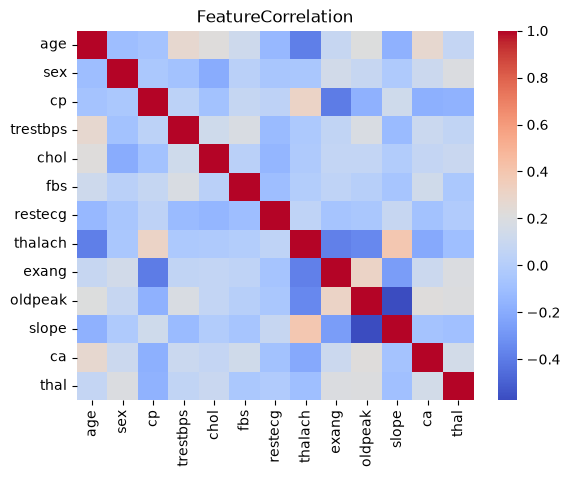

In [36]:
import matplotlib.pyplot as plt
sns.heatmap(X.corr(numeric_only=True),cmap="coolwarm") 
plt.title("FeatureCorrelation")
plt.show()

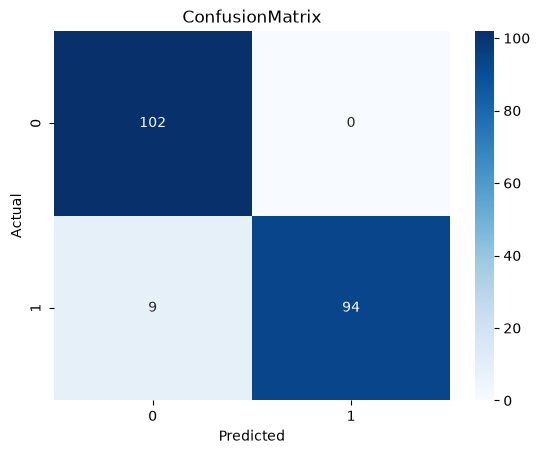

In [39]:
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("ConfusionMatrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

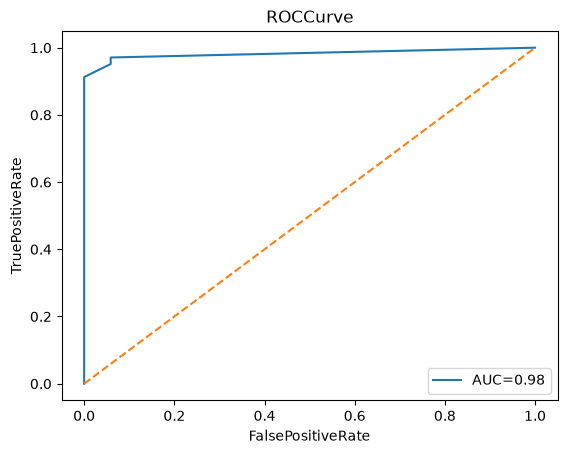

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix,roc_curve, auc 
from sklearn.decomposition import PCA 
from sklearn.tree import plot_tree
y_prob=best_model1.predict_proba(X_test_encoded)[:,1]
fpr,tpr,thresholds=roc_curve(y_test,y_prob)
plt.plot(fpr,tpr,label=f"AUC={auc(fpr,tpr):.2f}")
plt.plot([0,1],[0,1],"--")
plt.title("ROCCurve")
plt.xlabel("FalsePositiveRate")
plt.ylabel("TruePositiveRate")
plt.legend()
plt.show()

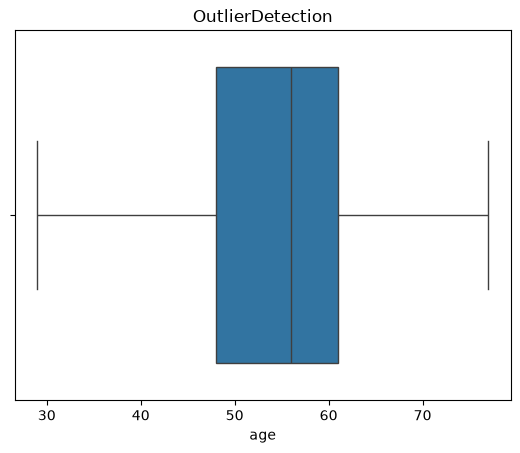

In [46]:
sns.boxplot(x=X['age'])
plt.title("OutlierDetection")
plt.show()

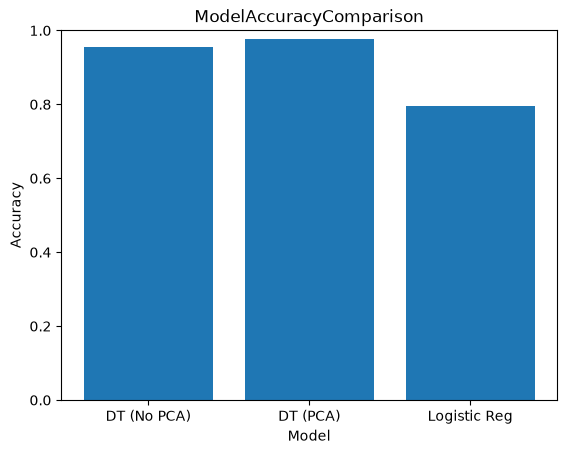

In [48]:
model_names = ['DT (No PCA)', 'DT (PCA)', 'Logistic Reg']
log_reg.fit(X_train_encoded, y_train)
accuracy_values = [
    accuracy_score(y_test, y_pred_dt),
    accuracy_score(y_test, y_pred_pca),
    accuracy_score(y_test, log_reg.predict(X_test_encoded))
]
plt.bar(model_names,accuracy_values) 
plt.title("ModelAccuracyComparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.show()

In [50]:
from sklearn.neighbors import KNeighborsClassifier

In [51]:
param_grid_knn = {
    'n_neighbors': list(range(1, 10)),
    'algorithm': ['kd_tree', 'ball_tree']
}

# 2. Grid Search Template (Cheatsheet Sec 4, p. 3 & p. 5)
knn_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)
# KNN requires scaled features (already scaled in X_train_encoded)
knn_search.fit(X_train_encoded, y_train)

best_knn = knn_search.best_estimator_
y_pred_knn = best_knn.predict(X_test_encoded)

print("Best KNN Parameters:", knn_search.best_params_)
print("Best KNN CV Score  :", knn_search.best_score_)
print("KNN Test Accuracy  :", accuracy_score(y_test, y_pred_knn))

Best KNN Parameters: {'algorithm': 'kd_tree', 'n_neighbors': 1}
Best KNN CV Score  : 0.978048780487805
KNN Test Accuracy  : 0.9853658536585366


In [53]:
from sklearn.svm import SVC,SVR

In [63]:
param_grid_svc = {
    'kernel': ['linear', 'poly', 'rbf'],
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto']
}

svc_search = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=param_grid_svc,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)

import warnings
warnings.filterwarnings('ignore')    
         
    

In [64]:
svc_search.fit(X_train_encoded, y_train)

best_svc = svc_search.best_estimator_
y_pred_svc = best_svc.predict(X_test_encoded)

print("Best KNN Parameters:", svc_search.best_params_)
print("Best KNN CV Score  :", svc_search.best_score_)
print("KNN Test Accuracy  :", accuracy_score(y_test, y_pred_svc))

Best KNN Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best KNN CV Score  : 0.9658536585365853
KNN Test Accuracy  : 0.975609756097561


In [65]:
from sklearn.cluster import KMeans 
kmeans=KMeans( n_clusters=2,random_state=42 )
kmeans.fit(X_train_encoded) 
wcss=kmeans.inertia_ 
labels=kmeans.labels_ 


In [66]:
print(wcss)

9029.836638783465


In [68]:
print(labels)

[0 1 0 0 0 0 1 0 0 1 1 1 1 0 1 0 1 1 0 0 0 0 0 1 0 0 1 0 1 1 1 0 1 0 0 1 0
 0 1 1 0 1 0 0 1 0 1 1 1 1 0 1 0 1 0 1 0 0 1 1 1 1 0 1 0 1 0 1 0 1 0 0 0 0
 0 1 0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 1 0 0 0 0 1 1
 1 0 1 0 1 0 0 0 1 1 0 1 1 0 0 0 0 0 1 1 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0
 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0
 1 0 0 1 0 0 0 1 0 1 1 0 0 1 1 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 1 0 0 0 0 1 1 0 0 0 0 0 1 1 1 0 0 0 1 0 0 1 0 0 0 1 1 1 1 1 0 0 0 0 0 0
 0 1 0 1 0 1 1 1 1 1 1 0 1 1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 0 0 1 1 1 1 1 0
 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 0 0 1 0 1 0 1 0 0 0 0 0
 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0
 0 0 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0 0 0 1 1 0 1 0 1 0
 1 0 1 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 0 1 0 0 1 0
 0 0 0 0 0 1 0 0 0 1 0 0 

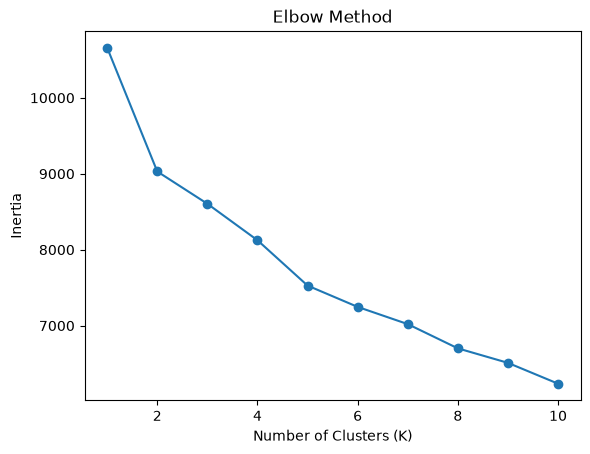

In [70]:
k_values=range(1,11)
inertia_values=[]

for k in k_values:
    km=KMeans(n_clusters=k,random_state=42)
    km.fit(X_train_encoded,y_train),
    inertia_values.append(km.inertia_)


plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

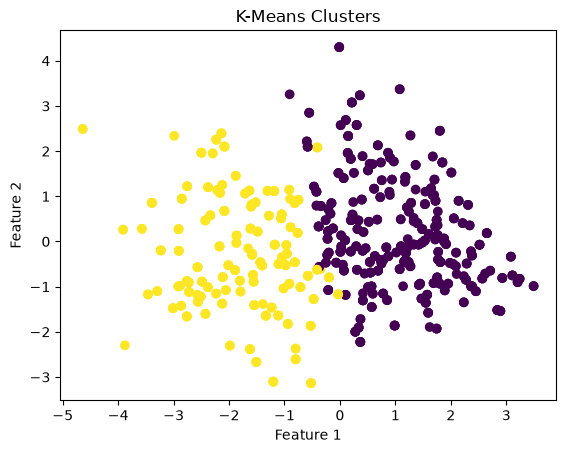

In [73]:
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=labels)
plt.title("K-Means Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

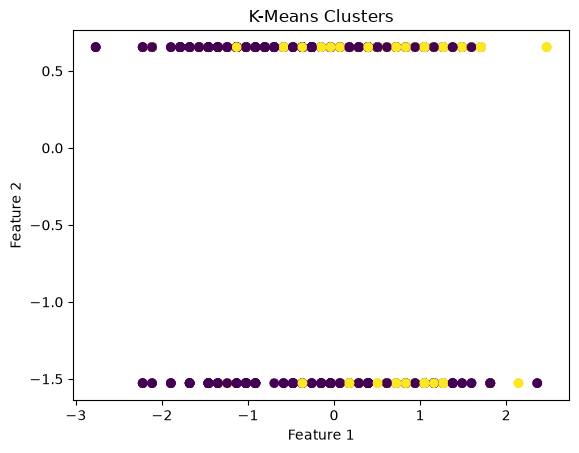

In [74]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA

# #10. K-MEANS CLUSTERS (Cheatsheet p. 6)
plt.scatter(X_train_encoded[:, 0], X_train_encoded[:, 1], c=labels, cmap="viridis")
plt.title("K-Means Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

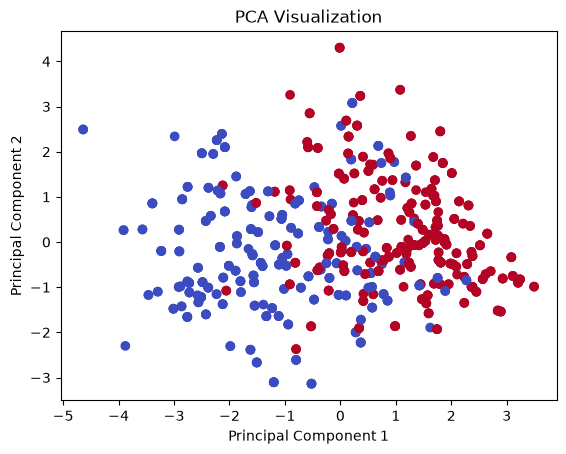

In [75]:
X_pca = PCA(n_components=2).fit_transform(X_train_encoded)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=pd.factorize(y_train)[0], cmap="coolwarm")
plt.title("PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

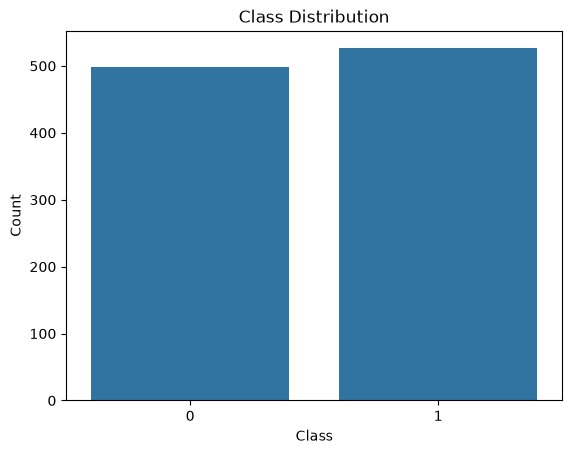

In [76]:
sns.countplot(x=y)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

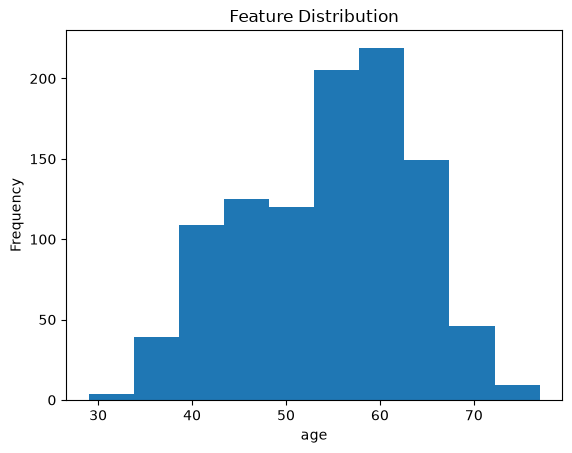

In [77]:
feature = X.columns[0]
plt.hist(X[feature], bins=10)
plt.title("Feature Distribution")
plt.xlabel(feature)
plt.ylabel("Frequency")
plt.show()

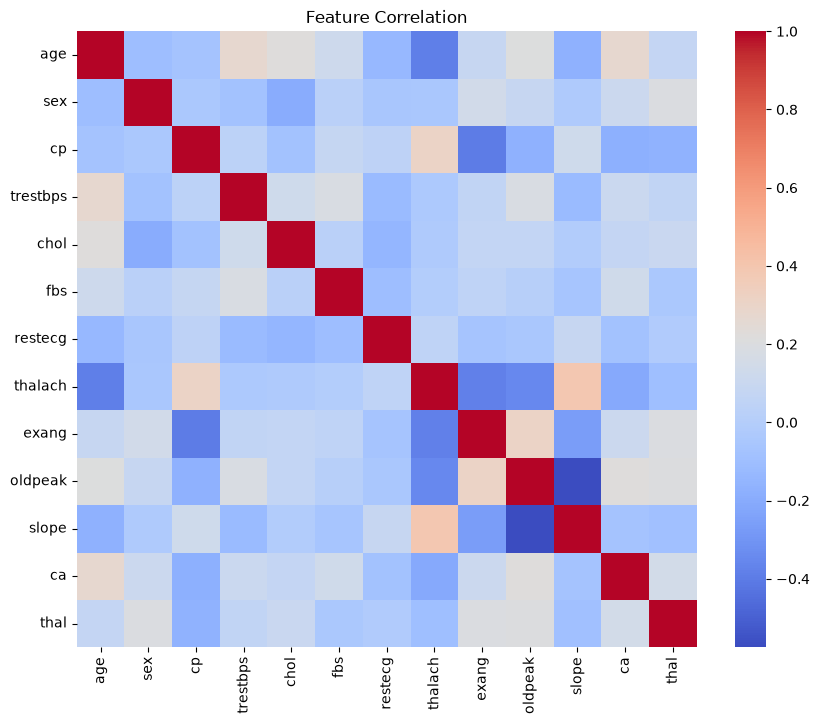

In [78]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

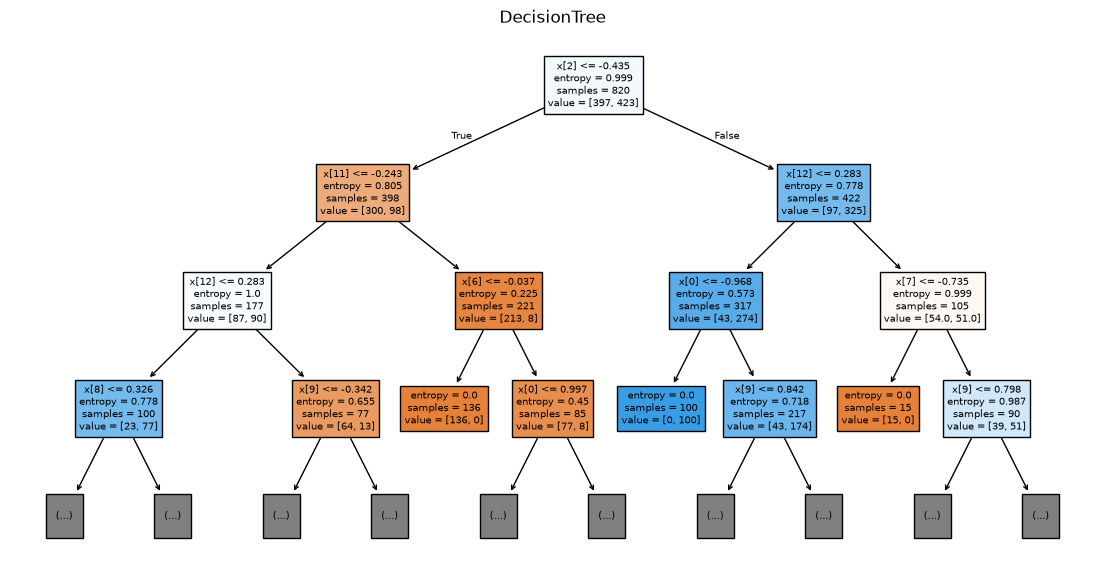

In [79]:
plt.figure(figsize=(14, 7)) 
plot_tree(best_model1,filled=True,max_depth=3) 
plt.title("DecisionTree")
plt.show()

In [80]:
feature1,feature2=X.columns[0],X.columns[1] plt.scatter(X[feature1],X[feature2],c=pd.factorize(y)[0]) plt.title("FeatureScatterPlot") plt.xlabel(feature1) plt.ylabel(feature2) plt.show()

SyntaxError: invalid syntax (136145464.py, line 1)